# EN4554 Assignment 1, Part 1: LoRA+ on SmolVLM-256M
## Notebook 03: are the grid results real? (3 fresh seeds)

Notebook 02 ran every (η_A, λ) setting **once** (seed 42). One run can be lucky or unlucky, so here the key settings are re-run with **3 new seeds (1, 2, 3)**. A seed changes the random start of the LoRA A matrices and the order of the training questions.

Using *new* seeds also keeps us honest. We **picked** the best settings using seed 42, so reporting seed 42's numbers would flatter them. The fresh seeds give an unbiased re-measurement.

**Settings re-run** (chosen from the notebook 02 grid):

| task | name | η_A | λ | why |
|---|---|---|---|---|
| TextVQA | LoRA-best | 8e-4 | 1 | best plain LoRA in the grid |
| TextVQA | LoRA+-best | 4e-4 | 8 | best LoRA+ in the grid |
| TextVQA | LoRA-lowlr | 1e-4 | 1 | plain LoRA at a typical small learning rate |
| TextVQA | LoRA+-lowlr | 1e-4 | 16 | same η_A, B 16× faster: tests the speed-up claim |
| VQAv2 | LoRA-best | 4e-4 | 1 | best plain LoRA in the grid |
| VQAv2 | LoRA+-best | 1e-4 | 16 | best LoRA+ in the grid (also the low-lr LoRA+ setting) |
| VQAv2 | LoRA-lowlr | 1e-4 | 1 | plain LoRA at the same η_A |

Each run also measures accuracy on 200 eval questions at steps 10, 20, 40, 70, 125 and 190, plus all 500 questions at the end (step 250). That gives accuracy-vs-step curves like the paper's Figure 7.


In [ ]:
!pip install -q "transformers==5.19.0" "peft==0.21.2" "datasets==5.1.0" accelerate
!pip uninstall -y -q torchao

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [ ]:
import os, sys, re, json, time, math, random, collections
import numpy as np
import torch

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/EN4554_LoRAplus"
else:
    ROOT = "./EN4554_LoRAplus"
DATA_DIR, RES_DIR = f"{ROOT}/data", f"{ROOT}/results"
os.makedirs(RES_DIR, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"                 # fp16 mixed precision on the T4 (no bf16 on T4)
SEED = 42

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

# ---------------- experiment settings ----------------
MODEL_ID = "HuggingFaceTB/SmolVLM-256M-Instruct"
RANK, ALPHA, DROPOUT = 8, 8, 0.0           # alpha = r = 8, as in the paper's Figures 3 and 4
# LoRA on every attention + MLP linear layer of BOTH the vision encoder and the language model
TARGET = r".*\.(vision_model|text_model)\..*\.(q_proj|k_proj|v_proj|o_proj|out_proj|gate_proj|up_proj|down_proj|fc1|fc2)"
EPOCHS, BATCH = 2, 16                       # 2 x 2000/16 = 250 optimiser steps per run
WARMUP_FRAC, MAX_GRAD_NORM = 0.06, 1.0      # linear warm-up for 6% of steps, then linear decay to 0

ETA_A = [1e-4, 2e-4, 4e-4, 8e-4, 1.6e-3]    # learning rate of A
# ratios lambda = eta_B / eta_A, in the order they are run (most important first).
# lambda = 1 is plain LoRA. The paper reports lambda ~ 2^2-2^3 for this initialisation (B = 0) and 2^4 as a common default.
GRID = {
    "textvqa": [1, 16, 4, 2, 8, 32],        # hard task: full grid for H1 (30 runs)
    "vqav2":   [1, 16, 4],                  # easy task: smaller grid for H2 (15 runs)
}
# Order in which (task, lambda) rows are run. The rows both hypotheses need come first,
# so if Colab's GPU quota runs out, H1 and H2 both already have data. The extra TextVQA rows come last.
RUN_ORDER = [("textvqa", 1), ("textvqa", 16), ("textvqa", 4),
             ("vqav2", 1), ("vqav2", 16), ("vqav2", 4),
             ("textvqa", 2), ("textvqa", 8), ("textvqa", 32)]
SUBSETS = {"textvqa": ("textvqa_train", "textvqa_eval"), "vqav2": ("vqav2_train", "vqav2_eval")}
EVAL_BATCH = 32

import transformers, peft, datasets
print("torch", torch.__version__, "| transformers", transformers.__version__, "| peft", peft.__version__,
      "| device", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

Mounted at /content/drive
torch 2.14.1+cu130 | transformers 5.19.0 | peft 0.21.2 | device cuda Tesla T4


## 1. Data, prompt and metric
These are the same as notebook 01: the same subsets from Drive, the same prompt, and the same VQA accuracy.

**Training target:** each question has 10 human answers, and we train on the **most common** one. The loss is computed **only on the answer tokens**. The image and question tokens get label `-100`, so they are ignored.

**Speed-up: images are pre-processed once per session.** SmolVLM's image processor is slow on Colab's CPU: it enlarges every image to 2048 px and then shrinks it to 512 px. Doing that for every batch of every run left the GPU waiting most of the time (about 13 min per run). So each task's images are processed **once**, kept in RAM as 8-bit images (about 2 GB per task; both tasks are kept, about 4 GB), and reused by every run.
This is **exact**: the processor's pixels are whole numbers 0–255, so storing them as 8-bit loses nothing. The check below compares a cached batch with a freshly processed one.

In [ ]:
from datasets import load_from_disk
from transformers import AutoProcessor, AutoModelForImageTextToText

data = {task: (load_from_disk(f"{DATA_DIR}/{tr}"), load_from_disk(f"{DATA_DIR}/{ev}")) for task, (tr, ev) in SUBSETS.items()}
for task, (tr, ev) in data.items():
    print(f"{task:8s} train {len(tr)}  eval {len(ev)}")

processor = AutoProcessor.from_pretrained(MODEL_ID, do_image_splitting=False)
tok = processor.tokenizer
EOU = "<end_of_utterance>"
PROMPT_SUFFIX = " Answer the question using a single word or phrase."

def build_prompt(question):
    msgs = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": question + PROMPT_SUFFIX}]}]
    return processor.apply_chat_template(msgs, add_generation_prompt=True)

def target_answer(answers):
    return collections.Counter(answers).most_common(1)[0][0]

def collate_train(rows):
    tok.padding_side = "right"
    answers = [target_answer(r["answers"]) for r in rows]
    texts = [build_prompt(r["question"]) + " " + a + EOU for r, a in zip(rows, answers)]
    batch = processor(text=texts, images=[[r["image"]] for r in rows], return_tensors="pt", padding=True)
    labels = torch.full_like(batch["input_ids"], -100)
    for i, a in enumerate(answers):                      # keep loss only on " answer<end_of_utterance>"
        n = len(tok(" " + a + EOU, add_special_tokens=False).input_ids)
        L = int(batch["attention_mask"][i].sum())
        labels[i, L - n:L] = batch["input_ids"][i, L - n:L]
    batch["labels"] = labels
    return batch

# check the masking once: the decoded label tokens must be exactly the answers
_b = collate_train([data["textvqa"][0][i] for i in range(3)])
for i in range(3):
    lab = _b["labels"][i]
    print("   trains on:", repr(tok.decode(lab[lab != -100])))

# ---- VQA accuracy (same as notebook 01) ----
_CONTRACTIONS = {"dont": "don't", "doesnt": "doesn't", "isnt": "isn't", "arent": "aren't", "cant": "can't",
                 "wont": "won't", "didnt": "didn't", "wasnt": "wasn't", "werent": "weren't", "couldnt": "couldn't",
                 "shouldnt": "shouldn't", "wouldnt": "wouldn't", "hasnt": "hasn't", "havent": "haven't",
                 "im": "i'm", "ive": "i've", "youre": "you're", "theyre": "they're", "thats": "that's",
                 "whats": "what's", "wheres": "where's", "hes": "he's", "shes": "she's", "lets": "let's"}
_NUMS = {"none": "0", "zero": "0", "one": "1", "two": "2", "three": "3", "four": "4", "five": "5",
         "six": "6", "seven": "7", "eight": "8", "nine": "9", "ten": "10"}
_ARTICLES = {"a", "an", "the"}
_PUNCT = [";", "/", "[", "]", '"', "{", "}", "(", ")", "=", "+", "\\", "_", "-", ">", "<", "@", "`", ",", "?", "!"]
_PERIOD = re.compile(r"(?!<=\d)(\.)(?!\d)")
_COMMA = re.compile(r"(\d)(,)(\d)")

def normalize_answer(s):
    s = s.replace("\n", " ").replace("\t", " ").strip().lower()
    out = s
    for p in _PUNCT:
        if (p + " " in s or " " + p in s) or _COMMA.search(s):
            out = out.replace(p, "")
        else:
            out = out.replace(p, " ")
    out = _PERIOD.sub("", out)
    words = []
    for w in out.split():
        w = _NUMS.get(w, w)
        if w in _ARTICLES:
            continue
        words.append(_CONTRACTIONS.get(w, w))
    return " ".join(words)

def vqa_score(pred, answers):
    p = normalize_answer(pred)
    gts = [normalize_answer(a) for a in answers]
    return float(np.mean([min(1.0, sum(g == p for g in gts[:i] + gts[i + 1:]) / 3.0) for i in range(len(gts))]))

# ---------------- one-time pre-processing cache ----------------
_ip = processor.image_processor
MEAN = torch.tensor(_ip.image_mean).view(1, 3, 1, 1)
STD = torch.tensor(_ip.image_std).view(1, 3, 1, 1)
RESCALE = _ip.rescale_factor

def to_uint8(pv):                  # processor output (B,1,3,H,W) floats -> (B,3,H,W) uint8, exact
    return ((pv[:, 0] * STD + MEAN) / RESCALE).round().clamp(0, 255).to(torch.uint8)

def from_uint8(u8, dtype):         # (B,3,H,W) uint8 on any device -> (B,1,3,H,W) normalised, as the processor makes it
    x = (u8.float() * RESCALE - MEAN.to(u8.device)) / STD.to(u8.device)
    return x.to(dtype)[:, None]

CACHE = {}

def prepare(task, split):
    # run the slow processor ONCE for every example of data[task] ('train' or 'eval'); keep token ids + uint8 images
    if (task, split) in CACHE:
        return CACHE[(task, split)]
    ds = data[task][0 if split == "train" else 1]
    t, ids, n_ans, imgs = time.time(), [], [], []
    tok.padding_side = "right"
    for i in range(0, len(ds), 64):
        chunk = ds[i:i + 64]
        if split == "train":
            answers = [target_answer(a) for a in chunk["answers"]]
            texts = [build_prompt(q) + " " + a + EOU for q, a in zip(chunk["question"], answers)]
            n_ans += [len(tok(" " + a + EOU, add_special_tokens=False).input_ids) for a in answers]
        else:
            texts = [build_prompt(q) for q in chunk["question"]]
        b = processor(text=texts, images=[[im] for im in chunk["image"]], return_tensors="pt", padding=True)
        ids += [b["input_ids"][k, :int(b["attention_mask"][k].sum())].clone() for k in range(len(texts))]
        imgs.append(to_uint8(b["pixel_values"]))
    CACHE[(task, split)] = c = {"img": torch.cat(imgs), "ids": ids, "n_ans": n_ans, "answers": list(ds["answers"])}
    print(f"   prepared {task}/{split}: {len(ids)} examples in {time.time()-t:.0f}s", flush=True)
    return c

def make_batch(c, idx, train):
    # pad token ids (right for training, left for generation) and attach the cached images
    seqs = [c["ids"][i] for i in idx]
    L, B = max(len(x) for x in seqs), len(seqs)
    input_ids = torch.full((B, L), tok.pad_token_id, dtype=torch.long)
    attn = torch.zeros((B, L), dtype=torch.long)
    labels = torch.full((B, L), -100, dtype=torch.long) if train else None
    for k, (i, x) in enumerate(zip(idx, seqs)):
        n = len(x)
        if train:
            input_ids[k, :n] = x; attn[k, :n] = 1
            labels[k, n - c["n_ans"][i]:n] = x[n - c["n_ans"][i]:]      # loss only on " answer<end_of_utterance>"
        else:
            input_ids[k, L - n:] = x; attn[k, L - n:] = 1
    out = {"input_ids": input_ids, "attention_mask": attn, "img": c["img"][list(idx)]}
    if train:
        out["labels"] = labels
    return out

def to_model_inputs(b, dtype):
    # move a cached batch to the GPU and rebuild pixel_values / pixel_attention_mask
    img = b.pop("img").to(DEVICE)
    b = {k: v.to(DEVICE) for k, v in b.items()}
    b["pixel_values"] = from_uint8(img, dtype)
    b["pixel_attention_mask"] = torch.ones((img.shape[0], 1, img.shape[2], img.shape[3]), dtype=torch.long, device=DEVICE)
    return b

@torch.no_grad()
def evaluate(model, c, n=None, batch_size=EVAL_BATCH, max_new_tokens=10):
    model.eval()
    N = n or len(c["ids"])
    dtype = next(model.parameters()).dtype
    preds = []
    for i in range(0, N, batch_size):
        b = to_model_inputs(make_batch(c, range(i, min(N, i + batch_size)), train=False), dtype)
        out = model.generate(**b, max_new_tokens=max_new_tokens, do_sample=False)
        preds += [x.strip() for x in processor.batch_decode(out[:, b["input_ids"].shape[1]:], skip_special_tokens=True)]
    scores = [vqa_score(p, a) for p, a in zip(preds, c["answers"][:N])]
    return 100 * float(np.mean(scores)), 100 * float(np.std(scores, ddof=1) / np.sqrt(len(scores))), preds

# ---------------- check: a cached batch is identical to a freshly processed one ----------------
_c = prepare("textvqa", "train")
_fresh = collate_train([data["textvqa"][0][i] for i in range(4)])
_cached = make_batch(_c, range(4), train=True)
_pv = from_uint8(_cached["img"], torch.float32)
assert torch.equal(_fresh["input_ids"], _cached["input_ids"]) and torch.equal(_fresh["labels"], _cached["labels"])
assert torch.equal(_fresh["attention_mask"], _cached["attention_mask"])
print("   cache check: token ids and labels identical, max pixel difference =",
      f"{(_fresh['pixel_values'] - _pv).abs().max().item():.1e}")
_ce = prepare("textvqa", "eval")
tok.padding_side = "left"                          # generation uses left padding
_fresh_e = processor(text=[build_prompt(q) for q in data["textvqa"][1][:4]["question"]],
                     images=[[im] for im in data["textvqa"][1][:4]["image"]], return_tensors="pt", padding=True)
assert torch.equal(_fresh_e["input_ids"], make_batch(_ce, range(4), train=False)["input_ids"]), "left padding differs"
print("   cache check (eval, left-padded prompts): identical")

textvqa  train 2000  eval 500
vqav2    train 2000  eval 500


processor_config.json:   0%|          | 0.00/68.0 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/516 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/486 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/7.35k [00:00<?, ?B/s]

[transformers] Model config: pad_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 128002. This may result in unexpected behavior.


... (3 outputs left out)

added_tokens.json:   0%|          | 0.00/4.74k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.55M [00:00<?, ?B/s]

   trains on: ' geuze boon<end_of_utterance>'
   trains on: ' yes<end_of_utterance>'
   trains on: ' upplandsmuseet<end_of_utterance>'
   prepared textvqa/train: 2000 examples in 78s
   cache check: token ids and labels identical, max pixel difference = 1.2e-07
   prepared textvqa/eval: 500 examples in 19s
   cache check (eval, left-padded prompts): identical


## 2. One training run = one (η_A, λ) pair
This is where LoRA+ happens. It is just **two optimiser parameter groups**:
* all `lora_A` matrices train with learning rate **η_A**;
* all `lora_B` matrices train with learning rate **η_B = λ · η_A**.

Everything else (warm-up, decay, gradient clipping, fp16 loss scaling) is identical for every run. A run whose loss becomes NaN/inf (learning rate too high) is stopped and recorded as **diverged**. That is a real outcome and shows up as an empty cell in the heat map.

In [ ]:
from peft import LoraConfig, get_peft_model
from torch.utils.data import DataLoader

def load_lora_model():
    dtype = torch.float16 if USE_AMP else torch.float32
    base = AutoModelForImageTextToText.from_pretrained(MODEL_ID, dtype=dtype).to(DEVICE)
    cfg = LoraConfig(r=RANK, lora_alpha=ALPHA, lora_dropout=DROPOUT, target_modules=TARGET)
    return get_peft_model(base, cfg)        # PEFT keeps the LoRA weights in fp32 even though the base is fp16

def results_file(task):
    return f"{RES_DIR}/grid_{task}.jsonl"

def load_results(task):
    if not os.path.exists(results_file(task)):
        return []
    with open(results_file(task)) as f:
        return [json.loads(l) for l in f if l.strip()]

def run_key(eta_a, ratio, seed):
    return f"{eta_a:.2e}|{ratio:g}|{seed}"

def train_one(task, eta_a, ratio, seed=SEED, epochs=EPOCHS, batch_size=BATCH, n_train=None, n_eval=None,
              curve_steps=(), curve_n=200):
    ctr, cev = prepare(task, "train"), prepare(task, "eval")
    n_tr = n_train or len(ctr["ids"])
    set_seed(seed)                                     # same LoRA init + same data order for every run
    model = load_lora_model()
    A = [p for n, p in model.named_parameters() if p.requires_grad and "lora_A" in n]
    B = [p for n, p in model.named_parameters() if p.requires_grad and "lora_B" in n]
    assert len(A) == len(B) and len(A) + len(B) == sum(p.requires_grad for p in model.parameters())
    opt = torch.optim.AdamW([{"params": A, "lr": eta_a}, {"params": B, "lr": eta_a * ratio}], weight_decay=0.0)

    loader = DataLoader(range(n_tr), batch_size=batch_size, shuffle=True,          # same shuffle order as before
                        collate_fn=lambda idx: make_batch(ctr, idx, train=True),
                        generator=torch.Generator().manual_seed(seed))
    total = epochs * len(loader)
    warm = max(1, int(WARMUP_FRAC * total))
    sched = torch.optim.lr_scheduler.LambdaLR(            # scales BOTH groups by the same factor -> ratio is preserved
        opt, lambda s: (s + 1) / warm if s < warm else max(0.0, (total - s) / max(1, total - warm)))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    model.train()
    losses, bad, diverged, t0, step = [], 0, False, time.time(), 0
    curve, curve_time = [], 0.0                       # (step, accuracy on the first curve_n eval questions)
    for epoch in range(epochs):
        for batch in loader:
            batch = to_model_inputs(batch, torch.float16 if USE_AMP else torch.float32)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                loss = model(**batch).loss
            if not torch.isfinite(loss):
                bad += 1
                opt.zero_grad(set_to_none=True)
                if bad >= 5:
                    diverged = True
                    break
                continue
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(A + B, MAX_GRAD_NORM)
            scaler.step(opt); scaler.update()
            opt.zero_grad(set_to_none=True); sched.step()
            losses.append(round(loss.item(), 4)); step += 1
            if step in curve_steps:
                tc = time.time()
                curve.append((step, evaluate(model, cev, n=curve_n)[0]))
                model.train(); curve_time += time.time() - tc
        if diverged:
            break
    train_time = time.time() - t0 - curve_time

    if diverged:
        acc, se, preds = None, None, None
    else:
        t1 = time.time()
        acc, se, preds = evaluate(model, cev, n=n_eval)
    rec = {"task": task, "eta_a": eta_a, "eta_b": eta_a * ratio, "ratio": ratio, "seed": seed,
           "acc": acc, "se": se, "diverged": diverged, "steps": step,
           "final_loss": round(float(np.mean(losses[-20:])), 4) if losses else None, "losses": losses,
           "train_time": round(train_time), "eval_time": None if diverged else round(time.time() - t1),
           "curve": curve, "preds": preds, "rank": RANK, "alpha": ALPHA, "epochs": epochs, "batch": batch_size, "n_train": n_tr, "n_eval": n_eval or len(cev["ids"])}
    del model, opt, A, B
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return rec

In [ ]:
CONFIGS = [  # (task, name, eta_A, lambda)
    ("textvqa", "LoRA-best",   8e-4, 1),
    ("textvqa", "LoRA+-best",  4e-4, 8),
    ("textvqa", "LoRA-lowlr",  1e-4, 1),
    ("textvqa", "LoRA+-lowlr", 1e-4, 16),
    ("vqav2",   "LoRA-best",   4e-4, 1),
    ("vqav2",   "LoRA+-best",  1e-4, 16),
    ("vqav2",   "LoRA-lowlr",  1e-4, 1),
]
SEEDS = [1, 2, 3]
CURVE_STEPS, CURVE_N = (10, 20, 40, 70, 125, 190), 200   # accuracy measured at these steps (front-loaded: speed differences are early)

def seeds_file(task):
    return f"{RES_DIR}/seeds_{task}.jsonl"

def load_seed_results(task):
    if not os.path.exists(seeds_file(task)):
        return []
    with open(seeds_file(task)) as f:
        return [json.loads(l) for l in f if l.strip()]

In [ ]:
done = {(r["task"], run_key(r["eta_a"], r["ratio"], r["seed"])) for t in ("textvqa", "vqav2") for r in load_seed_results(t)}
todo = [(s, c) for s in SEEDS for c in CONFIGS if (c[0], run_key(c[2], c[3], s)) not in done]
print(f"{len(todo)} runs to do")
times = []
for i, (seed, (task, name, eta_a, ratio)) in enumerate(todo, 1):
    prepare(task, "train"); prepare(task, "eval")
    t = time.time()
    rec = train_one(task, eta_a, ratio, seed=seed, curve_steps=CURVE_STEPS, curve_n=CURVE_N)
    rec["name"] = name
    with open(seeds_file(task), "a") as f:
        f.write(json.dumps(rec) + "\n")
    times.append(time.time() - t)
    acc = "DIVERGED" if rec["diverged"] else f"{rec['acc']:5.1f}"
    print(f"[{i:2d}/{len(todo)}] seed {seed} {task:7s} {name:12s} eta_A={eta_a:.0e} lambda={ratio:<3g} | acc {acc} | "
          f"loss {rec['final_loss']} | {times[-1]:.0f}s | ~{np.mean(times) * (len(todo) - i) / 60:.0f} min left", flush=True)

5 runs to do


model.safetensors: reconstructing file:   0%|          |  0.00B /  513MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

[ 1/5] seed 3 textvqa LoRA-lowlr   eta_A=1e-04 lambda=1   | acc  40.0 | loss 0.6359 | 426s | ~28 min left


... (5 outputs left out)

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

[ 4/5] seed 3 vqav2   LoRA+-best   eta_A=1e-04 lambda=16  | acc  63.6 | loss 0.2957 | 405s | ~7 min left


Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

[ 5/5] seed 3 vqav2   LoRA-lowlr   eta_A=1e-04 lambda=1   | acc  63.3 | loss 0.5177 | 418s | ~0 min left


## Results
**Table:** mean ± standard deviation over the 3 seeds.

**Paired comparison:** each question is scored for both settings, and the scores are averaged over the seeds. Bootstrapping over the 500 questions then gives a 95% confidence interval for the **difference**. A paired comparison is much more precise than comparing two separate ± values, because both settings answer the same questions.
* **H1 (accuracy):** LoRA+-best − LoRA-best on each task.
* **Speed-up claim:** steps until the training loss (10-step average) drops below 1.0, LoRA-lowlr vs LoRA+-lowlr (same η_A).
* **H2:** is (LoRA+-best − LoRA-best) larger on TextVQA than on VQAv2?


task     setting        eta_A   λ |  acc mean ± sd (3 seeds) | steps to loss<1 | seeds done
textvqa  LoRA-best      8e-04   1 |              41.1 ±  0.7 |    [13, 25, 22] | 3
textvqa  LoRA+-best     4e-04   8 |              39.4 ±  0.3 |    [13, 10, 22] | 3
textvqa  LoRA-lowlr     1e-04   1 |              40.1 ±  0.5 |    [43, 31, 30] | 3
textvqa  LoRA+-lowlr    1e-04  16 |              40.7 ±  0.8 |    [13, 13, 22] | 3
vqav2    LoRA-best      4e-04   1 |              63.4 ±  0.9 |    [13, 12, 14] | 3
vqav2    LoRA+-best     1e-04  16 |              63.4 ±  0.3 |       [8, 6, 7] | 3
vqav2    LoRA-lowlr     1e-04   1 |              62.8 ±  0.8 |    [37, 29, 44] | 3

H1 textvqa : LoRA+-best − LoRA-best = -1.7 points, 95% CI [-3.7, +0.3]   (zero-shot 32.8)
H1 vqav2   : LoRA+-best − LoRA-best = -0.0 points, 95% CI [-1.7, +1.6]   (zero-shot 45.3)
H2: gain(TextVQA) − gain(VQAv2) = -1.7 points, 95% CI [-4.2, +0.9]   (H2 predicts > 0)


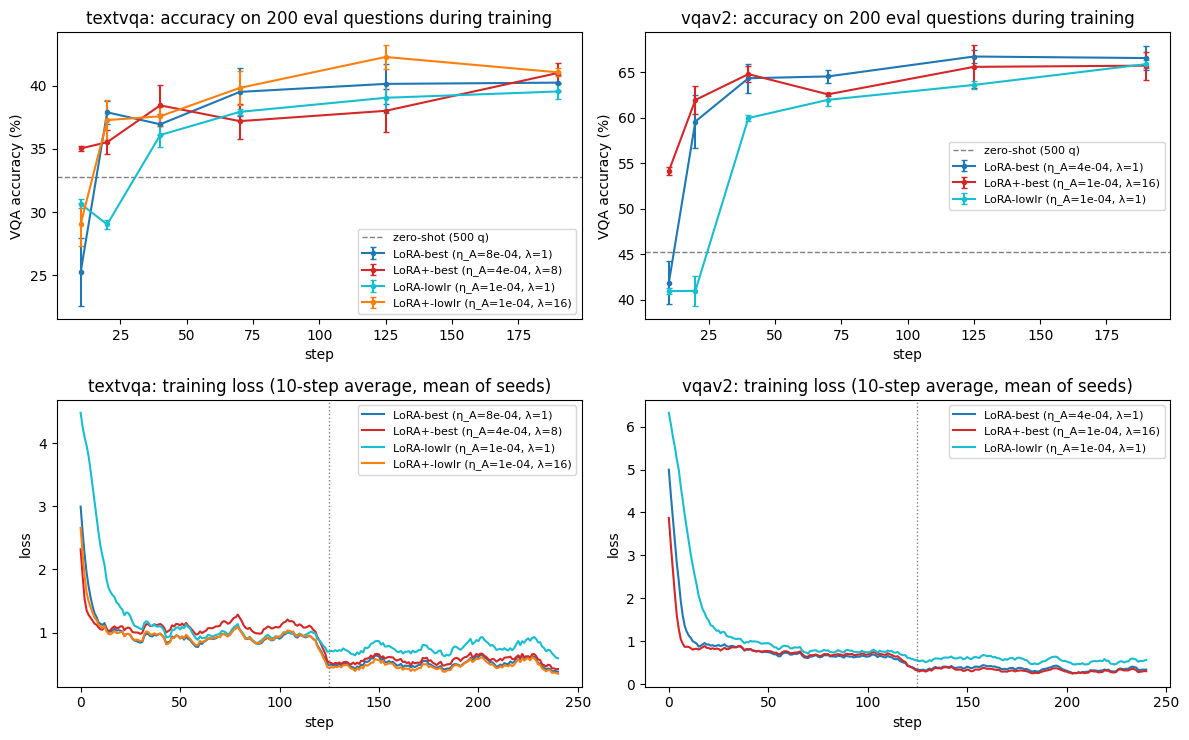

In [ ]:
import matplotlib.pyplot as plt

def per_question(rec, task):
    answers = prepare(task, "eval")["answers"]
    return np.array([vqa_score(p, a) for p, a in zip(rec["preds"], answers)])

def steps_below(losses, thr=1.0, k=10):
    s = np.convolve(np.asarray(losses, float), np.ones(k) / k, mode="valid")
    return int(np.argmax(s < thr)) if (s < thr).any() else None

rng = np.random.default_rng(0)
def boot_ci(diff, n=10000):
    idx = rng.integers(0, len(diff), size=(n, len(diff)))
    m = diff[idx].mean(1)
    return 100 * np.percentile(m, 2.5), 100 * np.percentile(m, 97.5)

summary, Q = {}, {}
print(f"{'task':8s} {'setting':12s} {'eta_A':>7s} {'λ':>3s} | {'acc mean ± sd (3 seeds)':>24s} | steps to loss<1 | seeds done")
for task, name, eta_a, ratio in CONFIGS:
    rs = [r for r in load_seed_results(task) if r.get("name") == name and not r["diverged"]]
    if not rs:
        continue
    accs = [r["acc"] for r in rs]
    sp = [steps_below(r["losses"]) for r in rs]
    Q[(task, name)] = np.mean([per_question(r, task) for r in rs], axis=0)
    summary[(task, name)] = {"eta_a": eta_a, "ratio": ratio, "acc_mean": float(np.mean(accs)),
                             "acc_sd": float(np.std(accs, ddof=1)) if len(accs) > 1 else None,
                             "accs": accs, "steps_to_loss_1": sp, "n_seeds": len(rs)}
    sd = f"{np.std(accs, ddof=1):.1f}" if len(accs) > 1 else "-"
    print(f"{task:8s} {name:12s} {eta_a:7.0e} {ratio:3g} | {np.mean(accs):17.1f} ± {sd:>4s} | {str(sp):>15s} | {len(rs)}")

zs = json.load(open(f"{RES_DIR}/zeroshot.json"))
print()
gains = {}
for task in ("textvqa", "vqav2"):
    if (task, "LoRA-best") in Q and (task, "LoRA+-best") in Q:
        d = Q[(task, "LoRA+-best")] - Q[(task, "LoRA-best")]
        gains[task] = d
        lo, hi = boot_ci(d)
        print(f"H1 {task:8s}: LoRA+-best − LoRA-best = {100*d.mean():+.1f} points, 95% CI [{lo:+.1f}, {hi:+.1f}]"
              f"   (zero-shot {zs[f'zeroshot_{task}']['acc']:.1f})")
if len(gains) == 2:
    i1 = rng.integers(0, len(gains["textvqa"]), size=(10000, len(gains["textvqa"])))
    i2 = rng.integers(0, len(gains["vqav2"]), size=(10000, len(gains["vqav2"])))
    dd = 100 * (gains["textvqa"][i1].mean(1) - gains["vqav2"][i2].mean(1))
    print(f"H2: gain(TextVQA) − gain(VQAv2) = {100*(gains['textvqa'].mean()-gains['vqav2'].mean()):+.1f} points, "
          f"95% CI [{np.percentile(dd, 2.5):+.1f}, {np.percentile(dd, 97.5):+.1f}]   (H2 predicts > 0)")
json.dump({f"{t}|{n}": v for (t, n), v in summary.items()}, open(f"{RES_DIR}/seeds_summary.json", "w"), indent=2)

# ---- figure: accuracy vs step (mean over seeds) and training loss, for both tasks
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
colors = {"LoRA-best": "tab:blue", "LoRA+-best": "tab:red", "LoRA-lowlr": "tab:cyan", "LoRA+-lowlr": "tab:orange"}
for col, task in enumerate(("textvqa", "vqav2")):
    for task_, name, eta_a, ratio in CONFIGS:
        if task_ != task:
            continue
        rs = [r for r in load_seed_results(task) if r.get("name") == name and not r["diverged"] and r["curve"]]
        if not rs:
            continue
        lab = f"{name} (η_A={eta_a:.0e}, λ={ratio:g})"
        steps = [s for s, _ in rs[0]["curve"]]
        acc = np.array([[a for _, a in r["curve"]] for r in rs])
        axes[0, col].errorbar(steps, acc.mean(0), yerr=acc.std(0) if len(rs) > 1 else None, color=colors[name],
                              label=lab, marker="o", ms=3, capsize=2)
        L = np.array([np.convolve(r["losses"], np.ones(10) / 10, mode="valid") for r in rs])
        axes[1, col].plot(L.mean(0), color=colors[name], label=lab)
    axes[0, col].axhline(zs[f"zeroshot_{task}"]["acc"], color="grey", ls="--", lw=1, label="zero-shot (500 q)")
    axes[0, col].set_title(f"{task}: accuracy on 200 eval questions during training")
    axes[0, col].set_xlabel("step"); axes[0, col].set_ylabel("VQA accuracy (%)"); axes[0, col].legend(fontsize=8)
    axes[1, col].set_title(f"{task}: training loss (10-step average, mean of seeds)")
    axes[1, col].set_xlabel("step"); axes[1, col].set_ylabel("loss"); axes[1, col].legend(fontsize=8)
    axes[1, col].axvline(125, color="grey", ls=":", lw=1)
plt.tight_layout(); plt.savefig(f"{RES_DIR}/seeds_curves.png", dpi=200); plt.show()